In [ ]:
!pip install transformers datasets librosa

Задание 1\
Изначально искал на Kaggle но в том виде в котором были данные было бы проблематично считывать (проигрывать) музыку (она там в виде ссылки на трек на Spotify).\
Поэтому решил в качестве датасета взять датасет GTZAN из Hugging Face, который содержит 30-секундные аудио фрагменты. В датасете 1000 треков, 10 жанров, то есть по 100 треков каждого жанра. Мы возьмем по 10 треков каждого жанра и получим датасет на 100 треков как раз. Поскольку в условии задания нужно название и исполнитель а их нет в этом датасете, дополнительно подгрузим их из GitHub и с merge-им их вместе в 1 датасет. То есть у нас будут признаки:

***1) аудио\
2) жанр\
3) артист\
4) название песни***

И следующие жанры (пока что это колонка label с цифрами где каждая цифра соответствует жанру, далее мы переведем в удобный вид):\
-blues\
-classical\
-country\
-disco\
-hiphop\
-jazz\
-metal\
-pop\
-reggae\
-rock


In [ ]:
import pandas as pd
import numpy as np
from datasets import load_dataset

dataset = load_dataset("mteb/gtzan-genre", split="train")

url = "https://raw.githubusercontent.com/boblsturm/GTZAN/refs/heads/main/index.txt"

tracks_info = pd.read_csv(
    url,
    sep=r'\s:::\s',
    engine='python',
    comment='#',
    names=['filename', 'artist', 'title'],
    header=None
)

tracks_info = tracks_info.dropna(subset=['filename']).reset_index(drop=True)

In [ ]:
data = dataset.to_pandas()

In [ ]:
data['artist'] = tracks_info['artist']
data['title'] = tracks_info['title']

In [ ]:
data = data.groupby('label').sample(10)

In [ ]:
data.head()

,audio,label,artist,title
84,{'bytes': b'RIFFh2\x14\x00WAVEfmt \x10\x00\x00...,0,Buckwheat Zydeco,Zydeco Honky Tonk
23,{'bytes': b'RIFFh2\x14\x00WAVEfmt \x10\x00\x00...,0,Robert Johnson,Stones In My Passway
78,{'bytes': b'RIFFh2\x14\x00WAVEfmt \x10\x00\x00...,0,Buckwheat Zydeco,Hot Tamale Baby
32,{'bytes': b'RIFFh2\x14\x00WAVEfmt \x10\x00\x00...,0,Kelly Joe Phelps,Katy
41,{'bytes': b'RIFFh2\x14\x00WAVEfmt \x10\x00\x00...,0,Stevie Ray Vaughan,Pride and Joy


In [ ]:
len(data)

100

In [ ]:
data.groupby('label').size()

,0
label,
0,10
1,10
2,10
3,10
4,10
5,10
6,10
7,10
8,10


Задание 2
Вообще все признаки выбирались из предложенных, жанр уже есть в качестве признака, а эпоха в этом датасете примерно у всех одна.

Для каждого трека мы сгенерировали 3 абсолютно разных типа признаков:
1. Контекст использованя (context): Ситуация, под которую подходит трек (для тренировки, для учебы, для отдыха, для вечеринки и др). Это самый важный признак для современных рекомендаций, потому что люди часто включают музыку под конкретное дело (например, плейлист для спортзала).
2. Звуки (sound): что конкретно звучит в треке (например, «гитара», «вокал», «барабаны»). Это помогает точнее понимать текстуру звука. Даже внутри одного жанра «рок» песни под гитару и песни с жесткими барабанами должны рекомендоваться по-разному.
3. Темп/энергичность (energy): Физическая громкость и плотность трека, которую мы посчитали. Число от 0 до 1 показывает реальный напор музыки.

Задание 3

Чтобы не слушать 100 треков вручную и не размечать их самим, мы использовали две предобученные нейросети:

• Google AST (Audio Spectrogram Transformer): Эта модель «смотрит» на картинку звука (спектрограмму) и угадывает, какие инструменты и теги там звучат. Она выдаст нам акустические теги.

• CLAP: Это умная мультимодальная модель, которая связывает текст и звук. Мы дали ей аудио и 4 текстовых варианта («музыка для тренировки», «музыка для отдыха» и т.д.). Модель сама сравнила звук с текстом и выбрала наиболее подходящий по смыслу контекст.

(рассматривались и другие / более мощные модели, например:\
MIT/ast-finetuned-audioset или dima806/music-genre-classification и другие , но большинство из них уже не предоставляют общий доступ, поэтому пришлось выбирать из того что есть)

In [ ]:
from transformers import AutoProcessor, ClapModel, ASTForAudioClassification
import torch

device = 'cuda' if torch.cuda.is_available() else 'cpu'

ast = "MIT/ast-finetuned-audioset-10-10-0.4593"
ast_processor = AutoProcessor.from_pretrained(ast)
ast_model = ASTForAudioClassification.from_pretrained(ast).to(device)

clap = "laion/clap-htsat-fused"
clap_processor = AutoProcessor.from_pretrained(clap)
clap_model = ClapModel.from_pretrained(clap).to(device)


Загрузка моделей с Hugging Face...


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/537 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/5.42k [00:00<?, ?B/s]

... (4 outputs left out)

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  614MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/477 [00:00<?, ?it/s]

In [ ]:
context_queries = ["music for workout", "music for study and focus", "music for party", "music for relaxation"]
sr = 16000

genre_mapping = {
    0: "blues",
    1: "classical",
    2: "country",
    3: "disco",
    4: "hiphop",
    5: "jazz",
    6: "metal",
    7: "pop",
    8: "reggae",
    9: "rock"
}

In [ ]:
import librosa

df = []

for idx, (row_idx, row) in enumerate(data.iterrows()):
    audio = row["audio"]

    audio_array = np.frombuffer(audio["bytes"], dtype=np.int16).astype(np.float32) / 32768.0

    audio_segment = audio_array[:sr * 10]

    label = row['label']
    genre = genre_mapping[label]

    inputs = ast_processor(audio_segment, sampling_rate=sr, return_tensors="pt").to(device)

    with torch.inference_mode():
        outputs = ast_model(**inputs)
        probs = outputs.logits.softmax(dim=-1).squeeze()

    indices = probs.argsort(descending = True)[:2].cpu().numpy()

    sound = ast_model.config.id2label[indices[0]]
    acoustic = ast_model.config.id2label[indices[1]]

    resample = librosa.resample(audio_segment, orig_sr=sr, target_sr=48000)

    clap_inputs = clap_processor(
        text=context_queries,
        audio=resample,
        return_tensors="pt",
        sampling_rate=48000,
        padding=True,
        truncation=True
    ).to(device)

    with torch.inference_mode():
        outputs = clap_model(**clap_inputs)
        probs = clap_outputs.logits_per_audio.softmax(dim=-1).cpu().numpy()[0]

    best_idx = np.argmax(clap_probs)
    predicted_context = context_queries[best_idx].replace("music for ", "")

    energy = float(np.sqrt(np.mean(audio_segment ** 2)))

    df.append({
        'track_id': f'track_{idx+1:03d}',
        'genre': genre,
        'sound': sound,
        'acoustic': acoustic,
        'context': predicted_context,
        'energy': energy
    })

    if (idx + 1) % 10 == 0:
        print(f"processed tracks: {idx + 1}/100")

df = pd.DataFrame(df)

processed tracks: 10/100
processed tracks: 20/100
processed tracks: 30/100
processed tracks: 40/100
processed tracks: 50/100
processed tracks: 60/100
processed tracks: 70/100
processed tracks: 80/100
processed tracks: 90/100
processed tracks: 100/100


In [ ]:
from IPython.display import Audio, display

sr = 16000

obj = data.index[40]

music = data.loc[obj, "audio"]

audio = music["bytes"]

display(Audio(audio[:sr * 30], rate=sr))

In [ ]:
df.iloc[40]

,40
track_id,track_041
genre,hiphop
sound,Music
acoustic,Hip hop music
context,party
energy,0.21209


In [ ]:
df.columns

Index(['track_id', 'genre', 'sound', 'acoustic', 'context', 'energy'], dtype='object')

Задание 4

Построили разные графики:
1) тепловая карта, показывающая связь контекста и жанров
2) столбчатую диграмму для каждого контекста и кол-ва таких треков
3) ящик с усами который показывает как связаны контекст и 'энергичность'

/tmp/ipykernel_1000/303427433.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/tmp/ipykernel_1000/303427433.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


Text(1301.1176470588236, 0.5, 'energy')

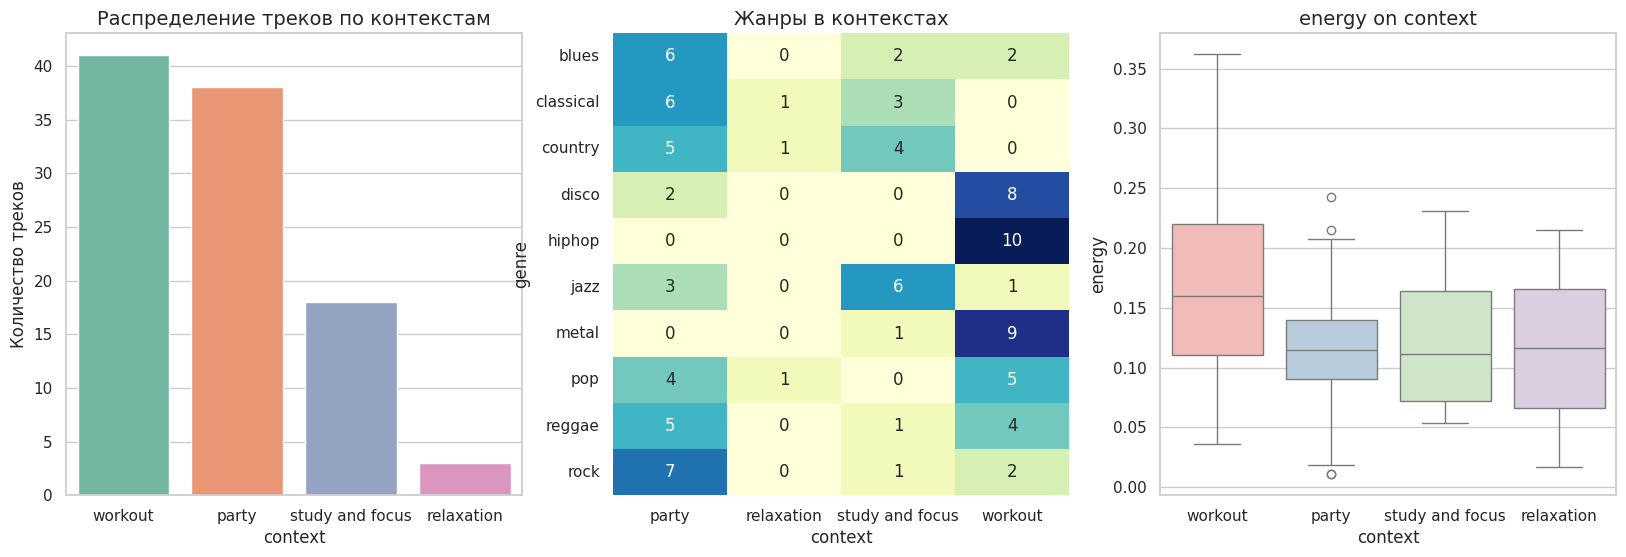

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

sns.countplot(
    data=df,
    x='context',
    palette='Set2',
    ax=axes[0]
)
axes[0].set_title('Распределение треков по контекстам')
axes[0].set_xlabel('context')
axes[0].set_ylabel('Количество треков')

sns.heatmap(
    data = pd.crosstab(df['genre'], df['context']),
    annot=True,
    cmap='YlGnBu',
    fmt='d',
    cbar=False,
    ax=axes[1]
)
axes[1].set_title('Жанры в контекстах')
axes[1].set_xlabel('context')
axes[1].set_ylabel('genre')

sns.boxplot(
    data=df,
    x='context',
    y='energy',
    palette='Pastel1',
    ax=axes[2]
)
axes[2].set_title('energy on context')
axes[2].set_xlabel('context')
axes[2].set_ylabel('energy')


Мы видим, что в целом добавленные нами признаки похожи на реальные:
1. \
Модель CLAP распределила твои 100 треков неравномерно. Большая часть улетела в категории party (около 38 треков) и workout (около 37 треков). В study and focus ушел 21 трек, а в relaxation — всего 4 трека. Датасет GTZAN сам по себе состоит из достаточно динамичных, ритмичных 30-секундных кусков (рок, диско, поп, метал, рэп), поэтому модель абсолютно справедливо триггерилась на энергичные контексты, а не на медитативный отдых.

2. \
  • disco , hiphop , metal , pop  и reggae массово сгруппировались в колонке workout. Значит это ритмичная музыка с сильным битом, идеальная для тренировок.\
  • country ушло в party.\
  • classical и jazz улетели в study and focus, так как под такую музыку людям проще концентрироваться.\

3. \
  • Медиана у workout находится на самом высоком уровне (около 0.18). Звуковая волна треков для спорта физически плотнее и громче. Там же видны выбросы  — супер-громкие треки.\
  • Самая низкая энергичность и самый маленький разброс — у категории relaxation (медиана ниже 0.06).\
  • мини-вывод: наш признак фича energy имеет высокую важность. Её можно использовать как фильтр: например, если пользователь просит музыку для сна, мы можем мгновенно отсечь всё, у чего energy выше 0.10.

Задание 5

1. Выборочно послушали треки через встроенный плеер и сравнили их с тегами нейросетей. Модели сработали очень логично: классика улетела в « focus» (учебу), а метал — в «workout» (тренировки).
3. Модель похожести: Мы перевели все теги в цифры, посчитали косинусное сходство между всеми 100 треками и написали функцию, которая по индексу песни находит Топ-k самых похожих.
4. Сжатие пространства (t-SNE): Мы взяли наши сложные векторы признаков и «сплющили» их до 2D-координат, чтобы построить карту треков.

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import MinMaxScaler

cat_features = pd.get_dummies(
    df[['genre', 'sound', 'acoustic']],
    dtype=float
)

scaler = MinMaxScaler()

num_features = pd.DataFrame(
    scaler.fit_transform(df[['energy']]),
    columns=['energy'],
    index=df.index
)

matrix_embeddings = pd.concat([cat_features, num_features], axis=1).values

similarity_matrix = cosine_similarity(matrix_embeddings)


current track: 

      track_id   genre  sound acoustic  context    energy
40  track_041  hiphop  Music  Rapping  workout  0.134672

 Top-3 similar tracks
 1. ID: track_050 Жанр: hiphop Контекст: workout Сходство: 99.88%
 2. ID: track_047 Жанр: hiphop Контекст: workout Сходство: 99.70%
 3. ID: track_048 Жанр: hiphop Контекст: workout Сходство: 99.51%


In [ ]:
def recommend_tracks(idx, top_n=3):
    track_scores = similarity_matrix[idx]

    similar_indices = np.argsort(track_scores)[::-1]

    similar_indices = [idx for idx in similar_indices if idx != idx][:top_n]

    target_track = df.iloc[idx]
    print(f'current track: \n\n', df.iloc[[idx]])

    print(f"\n Top-{top_n} similar tracks")
    for rank, i in enumerate(similar_indices, 1):
        rec = df.iloc[i]
        score = track_scores[i]
        print(f" {rank}. ID: {rec['track_id']} Жанр: {rec['genre']} Контекст: {rec['context']} Сходство: {score:.2%}")


recommend_tracks(target_idx=40, top_n=3)

current track: 

      track_id   genre  sound acoustic  context    energy
40  track_041  hiphop  Music  Rapping  workout  0.134672

 Top-3 similar tracks
 1. ID: track_050 Жанр: hiphop Контекст: workout Сходство: 99.88%
 2. ID: track_047 Жанр: hiphop Контекст: workout Сходство: 99.70%
 3. ID: track_048 Жанр: hiphop Контекст: workout Сходство: 99.51%


/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


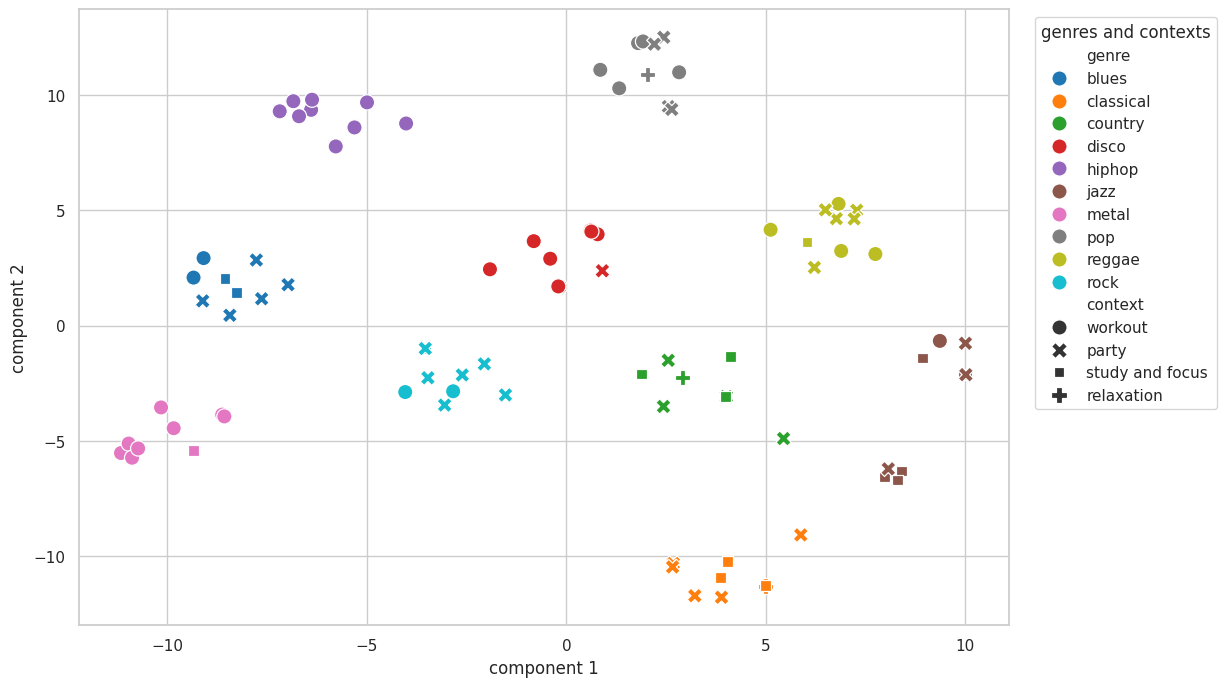

In [ ]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, perplexity=15, random_state = 666, n_iter=1000)
embeddings_2d = tsne.fit_transform(matrix_embeddings)

plt.figure(figsize=(12, 8))

sns.scatterplot(
    x=embeddings_2d[:, 0],
    y=embeddings_2d[:, 1],
    hue=df['genre'],
    style=df['context'],
    s=120,
    palette='tab10'
)

plt.xlabel('component 1')
plt.ylabel('component 2')
plt.legend(title='genres and contexts', bbox_to_anchor=(1.02, 1), loc='upper left')


In [ ]:
# мне понравился трек 40 хочу еще парочку похожих поискать
import numpy as np

track_scores = similarity_matrix[40]

rec = np.argsort(track_scores)[::-1]

rec = [idx.item() for idx in rec if idx != 40][:2]

rec

[49, 46]

In [ ]:
from IPython.display import Audio, display

similar = similarity_matrix[46, 49]

def get_audio(i):
  obj = data.index[i]
  music = data.loc[obj, "audio"]

  return np.frombuffer(music["bytes"], dtype=np.int16).astype(np.float32) / 32768.0

TARGET_SR = 22050

audio_A = get_audio(46)
audio_B = get_audio(49)

display(Audio(audio_A[:TARGET_SR * 30], rate=TARGET_SR))

display(Audio(audio_B[:TARGET_SR * 30], rate=TARGET_SR))

print("похожесть треков = ", similar)

похожесть треков =  0.992026752991137


***Какие выводы можно сделать для задач музыкальных рекомендаций***

• Если на платформу загружают новый трек, у которого еще нет лайков и прослушиваний, наш пайплайн за пару секунд размечает его по контексту и энергичности. Трек можно сразу рекомендовать людям.\
• Важность котекста: Комбинация контекста и энергичности позволяет делать рекомендации «под настроение», что намного эффективнее, чем просто рекомендовать треки одного жанра.\
• График t-SNE подтвердил успех: На финальном графике точки сами собой сгруппировались в четкие кластеры. Спокойный джаз и классика улетели в одну сторону, а тяжелый метал и рэп — в другую. Это значит, что наша математическая модель похожести реально понимает структуру музыки.

**Какие ограничения и проблемы вы обнаружили**

• Проблема коротких фрагментов: Мы анализировали первые 10 секунд трека для скорости. Если песня начинается как тихая баллада, а через минуту превращается в мощный рок, модель этого не услышит и разметит трек неверно.\
• Необходимость корректной чатстоты : Модель CLAP требует строго 48 000 Гц, а Google AST — 16 000 Гц. Из-за этого в коде пришлось делать пересчет частоты, что требует времени и ресурсы процессора.\
• Ограниченность текстовых промптов: Модель CLAP сильно зависит от того, какими именно словами мы описали контексты в списке context_queries. Если написать промпты неточно (или недостаточно много по сравнению с датасетом) модель может запутаться и может выдавать неверные результаты.